# Résultats sur DONNÉES FICTIVES — détection des incidents de cassettes

Exécuté sur une table **simulée** au format de la recette `cassettes_terminal_heure.sql` : 40 terminaux, du 01/09 au 08/11/2026, une ligne par terminal et par heure. **Les chiffres n'ont aucune valeur réelle.**

Incidents injectés :
- **T12301** (code regate 12301) : inversion des cassettes 10 € / 20 € du 04/11 12 h au 05/11 12 h, perte simulée 5 740 €, chargement du terminal tous les jours à 12 h. *Hypothèse de simulation* : le terminal sollicite davantage la position « 10 € » et des clients refont un retrait.
- **T75020** : valeur déclarée de la position 1 passée de 20 € à 10 € le 30/10 de 9 h à 18 h (paramétrage).
- **T69011** : cassette position 3 bloquée le 02/11 de 8 h à 18 h.
- **T13004** : retraits répétés par la même carte le 31/10 de 14 h à 20 h (signal faible).
- **T33010** : nouveau plan de cassettes à partir du 28/10 (changement légitime).
- T12302 à T12306 et 30 autres terminaux : normaux.

La section 1 a été réglée pour l'exécution : `CAS_CONNU = {"debut": "2026-11-04 12:00", "fin": "2026-11-05 12:00", "prefixe_site": "123", "perte_declaree": 5740}`.


# Détection des incidents de cassettes (inversion de coupures, paramétrage, cassette bloquée)

**Point de départ.** Une inversion de cassettes (billets de 10 € chargés à la place des 20 €, ou l'inverse) est rare,
coûteuse, et ne se voit pas dans le montant des retraits : le terminal enregistre ce qu'il **croit** distribuer.

**Ce qu'on cherche, terminal par terminal et heure par heure**, en comparant chaque fenêtre de 24 h à l'habitude du terminal
sur les 4 semaines précédentes :
1. **Répartition des billets entre cassettes** : une position sollicitée beaucoup plus (ou moins) que d'habitude.
2. **Valeur déclarée d'une cassette modifiée** : la position 1 vaut d'habitude 20 € et passe à 10 €.
3. **Retraits répétés par la même carte** dans les 10 minutes : clients qui n'ont pas reçu le bon montant.

Un seuil fixe ne convient pas à tous les terminaux : chaque signal est comparé au **maximum atteint par ce même terminal
pendant ses 4 semaines de référence**. Un événement est signalé quand le terminal fait ce qu'il n'a jamais fait.

**Chargements.** L'encaisse théorique baisse à chaque retrait et remonte d'un coup quand le terminal est rechargé.
Une inversion de cassettes se produit forcément à un chargement : une anomalie de répartition qui commence juste
après une remontée de l'encaisse renforce fortement la piste de l'inversion.

**Perte estimée.** Si une inversion 10 € / 20 € est confirmée, la perte vaut 10 € x (billets sortis des positions
« 10 € » - billets sortis des positions « 20 € ») sur la période : chaque billet sorti d'une position « 10 € »
était un 20 € (perte de 10 €), chaque billet sorti d'une position « 20 € » était un 10 € (gain de 10 €).

Entrée : dataset produit par la recette `cassettes_terminal_heure.sql` (une ligne par terminal, jour et heure).
Exécuter les cellules dans l'ordre. Seule la section 1 se modifie.

## 0. Imports

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

try:
    from scipy.stats import chi2
except ImportError:          # scipy absent : seuil théorique remplacé par le maximum de référence seul
    chi2 = None
pd.set_option("display.max_columns", 60)

## 1. Configuration

In [2]:
# ============================================================================================================
# BLOC À COMPLÉTER
# ============================================================================================================
DATASET_CASSETTES = "cassettes_terminal_heure"     # sortie de la recette cassettes_terminal_heure.sql
DEBUT_ANALYSE = "2026-10-26"                  # début de la période examinée (la référence est avant)
CAS_CONNU = {"debut": "2026-11-04 12:00", "fin": "2026-11-05 12:00", "prefixe_site": "123", "perte_declaree": 5740}                              # cas confirmé pour valider la méthode, ex. :
# CAS_CONNU = {"debut": "AAAA-MM-JJ HH:MM", "fin": "AAAA-MM-JJ HH:MM",
#              "prefixe_site": "123", "perte_declaree": 5000}
DATASET_SORTIE_EVENEMENTS = None              # ex. "incidents_cassettes" (dataset à créer dans le Flow)

# ============================================================================================================
# PARAMÈTRES DE LA MÉTHODE
# ============================================================================================================
JOURS_REFERENCE = 28          # habitude du terminal : 4 semaines avant DEBUT_ANALYSE
FENETRE_HEURES = 24           # fenêtre glissante examinée
MIN_BILLETS_FENETRE = 100     # en dessous, la répartition n'est pas interprétable
ECART_PART_MIN = 0.10         # écart minimal de part d'une position (10 points)
MARGE_REFERENCE = 1.5         # le signal doit dépasser 1,5 fois le maximum atteint en référence
MIN_REPETES = 5               # nombre minimal de retraits répétés dans la fenêtre
POSITIONS = [1, 2, 3, 4]

## 2. Fonctions d'affichage

In [3]:
BLEU, GRIS, GRIS_CLAIR, ORANGE, ENCRE = "#2a78d6", "#8a8984", "#d9d8d3", "#eb6834", "#0b0b0b"
COULEUR_COUPURE = {10: ORANGE, 20: BLEU, 50: GRIS, 5: ENCRE, 100: ENCRE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ececea", "grid.linewidth": 0.8, "axes.edgecolor": "#b5b4ae",
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
CSS = """<style>
.kpi-grille{display:flex;flex-wrap:wrap;gap:10px;margin:6px 0 14px}
.kpi{border:1px solid #e3e2de;border-radius:8px;padding:10px 14px;min-width:150px;background:#fcfcfb}
.kpi .v{font-size:22px;font-weight:700;color:#0b0b0b}.kpi .l{font-size:12px;color:#52514e}
table.t{border-collapse:collapse;font-size:12px;margin:4px 0 12px}
table.t th{background:#f3f2ef;color:#0b0b0b;text-align:left;padding:5px 9px;border-bottom:2px solid #d9d8d3}
table.t td{padding:4px 9px;border-bottom:1px solid #ecebe8;text-align:right}
table.t td.txt{text-align:left}
.note{color:#52514e;font-size:12.5px;margin:2px 0 10px;max-width:900px}
</style>"""


def echapper(texte):
    """Texte sûr dans du HTML."""
    return str(texte).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")


def formater(v):
    """Nombre lisible : séparateur de milliers, 1 décimale au plus."""
    if isinstance(v, (bool, np.bool_)):
        return "oui" if v else "non"
    if isinstance(v, (int, np.integer)):
        return "{:,}".format(int(v)).replace(",", " ")
    if isinstance(v, (float, np.floating)):
        if np.isnan(v):
            return "–"
        return "{:,.1f}".format(v).replace(",", " ") if abs(v) < 1000 else "{:,.0f}".format(v).replace(",", " ")
    if isinstance(v, pd.Timestamp):
        return v.strftime("%d/%m %Hh")
    return "" if v is None else str(v)


def afficher_titre(titre, note=None):
    html = CSS + "<h4 style='margin:10px 0 2px'>{}</h4>".format(titre)
    if note:
        html += "<div class='note'>{}</div>".format(note)
    display(HTML(html))


def afficher_chiffres(chiffres, titre=None):
    tuiles = "".join("<div class='kpi'><div class='v'>{}</div><div class='l'>{}</div></div>".format(
        echapper(formater(v)), k) for k, v in chiffres.items())
    display(HTML(CSS + ("<h4 style='margin:10px 0 2px'>{}</h4>".format(titre) if titre else "") +
                 "<div class='kpi-grille'>{}</div>".format(tuiles)))


def afficher_tableau(table, titre=None, note=None, max_lignes=40):
    if titre:
        afficher_titre(titre, note)
    if table is None or len(table) == 0:
        display(HTML(CSS + "<div class='note'>Aucune ligne.</div>"))
        return
    entete = "".join("<th>{}</th>".format(echapper(c)) for c in table.columns)
    corps = []
    for _, ligne in table.head(max_lignes).iterrows():
        cellules = "".join("<td class='{}'>{}</td>".format("txt" if isinstance(ligne[c], str) else "",
                                                          echapper(formater(ligne[c]))) for c in table.columns)
        corps.append("<tr>{}</tr>".format(cellules))
    display(HTML(CSS + "<table class='t'><tr>{}</tr>{}</table>".format(entete, "".join(corps))))

## 3. Lecture et grille horaire complète
Chaque terminal reçoit toutes les heures de la période : une heure sans retrait vaut 0 (elle n'existe pas dans la
recette). Les valeurs déclarées restent vides quand aucun billet n'est sorti.

In [4]:
def lire_dataset(nom):
    import dataiku
    return dataiku.Dataset(nom).get_dataframe()


brut = lire_dataset(DATASET_CASSETTES)
brut["ts"] = pd.to_datetime(brut["date_jour"].astype(str).str[:10]) + pd.to_timedelta(
    brut["heure"].astype(int), unit="h")
COMPTES = (["nb_retraits", "montant_total", "nb_montants_finissant_10", "nb_retraits_repetes_10min"] +
           ["nb_billets_pos{}".format(k) for k in POSITIONS] + ["nb_retraits_pos{}".format(k) for k in POSITIONS])
VALEURS = ["val_min_pos{}".format(k) for k in POSITIONS] + ["val_max_pos{}".format(k) for k in POSITIONS]
COMPTES_ENCAISSE = ["nb_recharges", "montant_recharge", "nb_incoherences_encaisse"]
VALEURS_ENCAISSE = ["encaisse_min_heure", "encaisse_max_heure"]
AVEC_ENCAISSE = all(c in brut.columns for c in COMPTES_ENCAISSE + VALEURS_ENCAISSE)
for c in COMPTES_ENCAISSE + VALEURS_ENCAISSE:
    if c not in brut.columns:
        brut[c] = 0 if c in COMPTES_ENCAISSE else np.nan
COMPTES = COMPTES + COMPTES_ENCAISSE
VALEURS = VALEURS + VALEURS_ENCAISSE
for c in COMPTES + VALEURS:
    brut[c] = pd.to_numeric(brut[c], errors="coerce")
brut[COMPTES] = brut[COMPTES].fillna(0)
for c in ["code_site_implantation", "cd_regate", "code_postal", "ville"]:
    if c not in brut.columns:
        brut[c] = ""
brut["num_automate"] = brut["num_automate"].astype(str)

DEBUT = pd.Timestamp(DEBUT_ANALYSE)
DEBUT_REF = DEBUT - pd.Timedelta(days=JOURS_REFERENCE)
FIN = brut["ts"].max().floor("D") + pd.Timedelta(hours=23)
brut = brut[(brut["ts"] >= DEBUT_REF) & (brut["ts"] <= FIN)]

infos = brut.groupby("num_automate")[["code_site_implantation", "cd_regate", "code_postal", "ville"]].agg(
    lambda s: s.dropna().astype(str).iloc[-1] if s.notna().any() else "")
heures = pd.date_range(DEBUT_REF, FIN, freq="H")
index = pd.MultiIndex.from_product([sorted(brut["num_automate"].unique()), heures], names=["num_automate", "ts"])
grille = brut.set_index(["num_automate", "ts"])[COMPTES + VALEURS].reindex(index)
grille[COMPTES] = grille[COMPTES].fillna(0)
grille = grille.reset_index()

afficher_chiffres({"terminal": grille["num_automate"].nunique(), "heures par terminal": len(heures),
                   "retraits": int(grille["nb_retraits"].sum()),
                   "chargements repérés": int(grille["nb_recharges"].sum()) if AVEC_ENCAISSE else "colonnes absentes",
                   "incohérences d'encaisse": int(grille["nb_incoherences_encaisse"].sum()) if AVEC_ENCAISSE else "–",
                   "référence": "{} → {}".format(DEBUT_REF.strftime("%d/%m"), (DEBUT - pd.Timedelta(days=1)).strftime("%d/%m")),
                   "période analysée": "{} → {}".format(DEBUT.strftime("%d/%m"), FIN.strftime("%d/%m"))},
                  "Données lues")

## 4. Habitude de chaque terminal (4 semaines de référence)
Pour chaque position : **part habituelle** des billets sortis et **valeur habituelle** (la valeur déclarée la plus
fréquente, pondérée par les billets). Taux habituel de retraits répétés par la même carte.

In [5]:
reference = grille[grille["ts"] < DEBUT]
habitude = pd.DataFrame(index=sorted(grille["num_automate"].unique()))
total_ref = reference.groupby("num_automate")[["nb_billets_pos{}".format(k) for k in POSITIONS]].sum()
for k in POSITIONS:
    habitude["part_ref_pos{}".format(k)] = total_ref["nb_billets_pos{}".format(k)] / total_ref.sum(axis=1).replace(0, np.nan)
    v = reference[reference["nb_billets_pos{}".format(k)] > 0].groupby(
        ["num_automate", "val_max_pos{}".format(k)])["nb_billets_pos{}".format(k)].sum().reset_index()
    v = v.sort_values("nb_billets_pos{}".format(k)).drop_duplicates("num_automate", keep="last")
    habitude["val_ref_pos{}".format(k)] = v.set_index("num_automate")["val_max_pos{}".format(k)]
somme_ref = reference.groupby("num_automate")[["nb_retraits", "nb_retraits_repetes_10min"]].sum()
habitude["taux_repetes_ref"] = (somme_ref["nb_retraits_repetes_10min"] / somme_ref["nb_retraits"].replace(0, np.nan))
habitude = habitude.fillna({"part_ref_pos{}".format(k): 0 for k in POSITIONS}).fillna({"taux_repetes_ref": 0})
recharges_ref = reference[reference["nb_recharges"] > 0]
habitude["chargements_par_semaine"] = (recharges_ref.groupby("num_automate").size() * 7 / JOURS_REFERENCE)
habitude["montant_charge_habituel"] = recharges_ref.groupby("num_automate")["montant_recharge"].median()
CHARGEMENTS = grille[grille["nb_recharges"] > 0][["num_automate", "ts", "montant_recharge"]]


def chargements_proches(terminal, t, marge_h=3):
    """Chargements du terminal à moins de marge_h heures de l'instant t (texte « 04/11 12h (31 000 €) »)."""
    c = CHARGEMENTS[(CHARGEMENTS["num_automate"] == terminal) &
                    ((CHARGEMENTS["ts"] - t).abs() <= pd.Timedelta(hours=marge_h))]
    return ", ".join("{} ({} €)".format(r.ts.strftime("%d/%m %Hh"), formater(r.montant_recharge)) for r in c.itertuples())


def plan_cassettes(terminal):
    """Texte « pos1 20 € (33 %) | pos2 ... » de l'habitude d'un terminal."""
    h = habitude.loc[terminal]
    return " | ".join("p{} {} € ({:.0f} %)".format(k, int(h["val_ref_pos{}".format(k)]) if not pd.isna(
        h["val_ref_pos{}".format(k)]) else "?", 100 * h["part_ref_pos{}".format(k)]) for k in POSITIONS)


apercu = habitude.reset_index().rename(columns={"index": "num_automate"}).head(8)
apercu["plan habituel des cassettes"] = apercu["num_automate"].map(plan_cassettes)
afficher_tableau(apercu[["num_automate", "plan habituel des cassettes", "taux_repetes_ref",
                         "chargements_par_semaine", "montant_charge_habituel"]],
                 "Habitude des premiers terminal",
                 "Valeur habituelle de chaque position et part des billets qui en sortent ; taux habituel de "
                 "retraits répétés par la même carte en moins de 10 minutes ; chargements par semaine et montant "
                 "habituellement chargé (remontées de l'encaisse théorique).")

num_automate,plan habituel des cassettes,taux_repetes_ref,chargements_par_semaine,montant_charge_habituel
T10000,p1 20 € (26 %) | p2 50 € (22 %) | p3 50 € (46 %) | p4 20 € (6 %),0.0,2.2,14 000
T10001,p1 20 € (8 %) | p2 20 € (62 %) | p3 50 € (17 %) | p4 10 € (14 %),0.0,2.2,19 840
T10002,p1 20 € (29 %) | p2 20 € (45 %) | p3 50 € (10 %) | p4 10 € (17 %),0.0,2.5,19 060
T10003,p1 20 € (27 %) | p2 50 € (23 %) | p3 50 € (33 %) | p4 20 € (18 %),0.0,2.5,11 000
T10004,p1 20 € (28 %) | p2 20 € (22 %) | p3 50 € (30 %) | p4 10 € (19 %),0.0,2.2,12 390
T10005,p1 20 € (38 %) | p2 20 € (22 %) | p3 50 € (36 %) | p4 10 € (4 %),0.0,2.5,37 445
T10006,p1 20 € (13 %) | p2 50 € (47 %) | p3 50 € (17 %) | p4 20 € (23 %),0.0,2.2,12 000
T10007,p1 20 € (30 %) | p2 20 € (25 %) | p3 50 € (19 %) | p4 10 € (26 %),0.0,2.2,10 330


## 5. Fenêtres glissantes de 24 h et signaux
Pour chaque terminal et chaque heure, on additionne les 24 dernières heures puis on calcule :
- **score_cassettes** : écart entre la répartition observée des billets et la répartition habituelle (statistique
  G du test du rapport de vraisemblance), divisé par le plus fort écart atteint par ce terminal en référence ;
- **ecart_part** : plus grand écart de part d'une position, en points ;
- **valeur_modifiee** : une position a sorti des billets avec une valeur déclarée différente de l'habitude ;
- **score_repetes** : excès de retraits répétés par rapport au taux habituel, divisé par le maximum de référence.

In [6]:
def sommes_glissantes(table, colonnes, n):
    """Somme sur les n dernières heures, terminal par terminal (grille complète et triée)."""
    cumul = table.groupby("num_automate")[colonnes].cumsum()
    decale = cumul.groupby(table["num_automate"]).shift(n)
    return cumul - decale


grille = grille.sort_values(["num_automate", "ts"]).reset_index(drop=True)
h = habitude.reindex(grille["num_automate"]).reset_index(drop=True)

# valeur déclarée différente de l'habitude, heure par heure
modif = np.zeros(len(grille))
perte_param = np.zeros(len(grille))
for k in POSITIONS:
    ref_v = h["val_ref_pos{}".format(k)].values
    vmin, vmax = grille["val_min_pos{}".format(k)].values, grille["val_max_pos{}".format(k)].values
    billets = grille["nb_billets_pos{}".format(k)].values
    change = (billets > 0) & ~np.isnan(ref_v) & ((vmin != ref_v) | (vmax != ref_v)) & ~np.isnan(vmax)
    modif += change
    perte_param += np.where(change, billets * (ref_v - np.nan_to_num(vmax)), 0)
grille["heure_valeur_modifiee"] = (modif > 0).astype(int)
grille["perte_parametrage"] = perte_param

# billets par coupure habituelle (pour la perte en cas d'inversion 10 / 20)
grille["billets_pos_10"] = sum(np.where(h["val_ref_pos{}".format(k)].values == 10,
                                        grille["nb_billets_pos{}".format(k)].values, 0) for k in POSITIONS)
grille["billets_pos_20"] = sum(np.where(h["val_ref_pos{}".format(k)].values == 20,
                                        grille["nb_billets_pos{}".format(k)].values, 0) for k in POSITIONS)

A_SOMMER = (["nb_billets_pos{}".format(k) for k in POSITIONS] +
            ["nb_retraits", "nb_retraits_repetes_10min", "heure_valeur_modifiee", "perte_parametrage",
             "billets_pos_10", "billets_pos_20"])
fen = sommes_glissantes(grille, A_SOMMER, FENETRE_HEURES)
fen["num_automate"], fen["ts"] = grille["num_automate"], grille["ts"]
fen = fen[fen["ts"] >= DEBUT_REF + pd.Timedelta(hours=FENETRE_HEURES - 1)].reset_index(drop=True)
hf = habitude.reindex(fen["num_automate"]).reset_index(drop=True)

# répartition entre positions : statistique G
O = fen[["nb_billets_pos{}".format(k) for k in POSITIONS]].values.astype(float)
B = O.sum(axis=1)
P = np.clip(hf[["part_ref_pos{}".format(k) for k in POSITIONS]].values, 1e-3, None)
P = P / P.sum(axis=1, keepdims=True)
E = B[:, None] * P
with np.errstate(divide="ignore", invalid="ignore"):
    G = 2 * np.where(O > 0, O * np.log(O / E), 0).sum(axis=1)
parts = np.where(B[:, None] > 0, O / np.where(B[:, None] > 0, B[:, None], 1), np.nan)
ecarts = parts - hf[["part_ref_pos{}".format(k) for k in POSITIONS]].values
fen["G"] = np.where(B >= MIN_BILLETS_FENETRE, G, np.nan)
fen["ecart_part"] = np.nanmax(np.abs(np.nan_to_num(ecarts)), axis=1)
fen["position_ecart"] = np.argmax(np.abs(np.nan_to_num(ecarts)), axis=1) + 1
fen["sens_ecart"] = np.sign(ecarts[np.arange(len(fen)), fen["position_ecart"].values - 1])
fen["nb_billets"] = B

# retraits répétés : écart au taux habituel, en écarts-types
r = hf["taux_repetes_ref"].values
n = fen["nb_retraits"].values
attendu = n * r
fen["z_repetes"] = (fen["nb_retraits_repetes_10min"].values - attendu) / np.sqrt(attendu * (1 - r) + 1)

# seuils propres à chaque terminal : maximum atteint pendant la référence
en_reference = fen["ts"] < DEBUT
max_ref = fen[en_reference].groupby("num_automate")[["G", "z_repetes"]].max()
plancher_G = chi2.ppf(0.9999, len(POSITIONS) - 1) if chi2 is not None else 20.0
seuil_G = np.maximum(max_ref["G"].reindex(fen["num_automate"]).values, plancher_G)
seuil_z = np.maximum(max_ref["z_repetes"].reindex(fen["num_automate"]).values, 4.0)
fen["score_cassettes"] = fen["G"] / seuil_G
fen["score_repetes"] = fen["z_repetes"] / seuil_z

fen["signal_cassettes"] = (fen["score_cassettes"] > MARGE_REFERENCE) & (fen["ecart_part"] >= ECART_PART_MIN)
fen["signal_valeur"] = fen["heure_valeur_modifiee"] > 0
fen["signal_repetes"] = (fen["score_repetes"] > MARGE_REFERENCE) & (fen["nb_retraits_repetes_10min"] >= MIN_REPETES)
fen["perte_si_inversion_10_20"] = 10 * (fen["billets_pos_10"] - fen["billets_pos_20"])
analyse = fen[fen["ts"] >= DEBUT + pd.Timedelta(hours=FENETRE_HEURES - 1)].copy()

afficher_chiffres({"fenêtres examinées": len(analyse),
                   "répartition anormale": int(analyse["signal_cassettes"].sum()),
                   "valeur déclarée modifiée": int(analyse["signal_valeur"].sum()),
                   "retraits répétés": int(analyse["signal_repetes"].sum())},
                  "Fenêtres de 24 h en alerte sur la période analysée")

## 6. Événements détectés sur tout le parc
Les fenêtres en alerte qui se suivent forment un **événement**. Pour chaque événement, on retient la fenêtre de
24 h la plus anormale et on propose une lecture :
- **inversion 10 € / 20 € possible** : répartition anormale, le terminal a des positions 10 € et 20 €, et des retraits
  répétés, une position 10 € sur-sollicitée ou un chargement juste avant le début de l'anomalie ;
- **erreur de paramétrage** : valeur déclarée modifiée puis revenue à l'habitude ;
- **nouveau plan de cassettes (à confirmer)** : valeur déclarée modifiée jusqu'à la fin des données ;
- **cassette vide ou bloquée** : une position sort moins du tiers de sa part habituelle ;
- **retraits répétés** : clients qui refont un retrait, sans changement de répartition.

In [7]:
analyse["alerte"] = analyse[["signal_cassettes", "signal_valeur", "signal_repetes"]].any(axis=1)
alertes = analyse[analyse["alerte"]].sort_values(["num_automate", "ts"]).copy()
alertes["nouvel_evenement"] = (alertes.groupby("num_automate")["ts"].diff() != pd.Timedelta(hours=1))
alertes["id_evenement"] = alertes["nouvel_evenement"].cumsum()
alertes["force"] = (alertes["score_cassettes"].fillna(0) + alertes["score_repetes"].clip(lower=0).fillna(0)
                    + 2 * alertes["signal_valeur"])


def lire_evenement(groupe):
    """Résumé d'un événement : fenêtre la plus anormale, signaux, lecture proposée, pertes estimées."""
    pic = groupe.loc[groupe["force"].idxmax()]
    terminal = pic["num_automate"]
    hab = habitude.loc[terminal]
    pos = int(pic["position_ecart"])
    val_pos = hab["val_ref_pos{}".format(pos)]
    vals = set(hab[["val_ref_pos{}".format(k) for k in POSITIONS]].dropna().astype(int))
    part_obs = pic["nb_billets_pos{}".format(pos)] / max(pic["nb_billets"], 1)
    signaux = [nom for nom, cle in [("répartition", "signal_cassettes"), ("valeur déclarée", "signal_valeur"),
                                    ("retraits répétés", "signal_repetes")] if groupe[cle].any()]
    dure_jusqua_fin = groupe["ts"].max() >= FIN - pd.Timedelta(hours=1)
    debut_pic = pic["ts"] - pd.Timedelta(hours=FENETRE_HEURES - 1)
    charge_debut = chargements_proches(terminal, debut_pic)
    charge_fin = chargements_proches(terminal, pic["ts"] + pd.Timedelta(hours=1))
    if groupe["signal_valeur"].any():
        lecture = "nouveau plan de cassettes (à confirmer)" if dure_jusqua_fin and len(groupe) > 48 \
            else "erreur de paramétrage de cassette"
    elif groupe["signal_cassettes"].any() and {10, 20} <= vals and (
            groupe["signal_repetes"].any() or (val_pos == 10 and pic["sens_ecart"] > 0) or charge_debut):
        lecture = "inversion 10 € / 20 € possible"
    elif groupe["signal_cassettes"].any() and pic["sens_ecart"] < 0 and part_obs < 0.35 * hab["part_ref_pos{}".format(pos)]:
        lecture = "cassette vide ou bloquée"
    elif groupe["signal_cassettes"].any():
        lecture = "répartition inhabituelle entre cassettes"
    else:
        lecture = "retraits répétés"
    return pd.Series({
        "num_automate": terminal, "site": infos.loc[terminal, "code_site_implantation"], "ville": infos.loc[terminal, "ville"],
        "lecture proposée": lecture, "signaux": ", ".join(signaux),
        "alerte du": groupe["ts"].min() - pd.Timedelta(hours=FENETRE_HEURES - 1), "au": groupe["ts"].max(),
        "24 h les plus anormales": "{} → {}".format(debut_pic.strftime("%d/%m %Hh"), pic["ts"].strftime("%d/%m %Hh")),
        "chargement au début": charge_debut or "non", "chargement à la fin": charge_fin or "non",
        "position en cause": "p{} ({} €)".format(pos, int(val_pos) if not pd.isna(val_pos) else "?"),
        "part habituelle %": 100 * hab["part_ref_pos{}".format(pos)], "part observée %": 100 * part_obs,
        "score cassettes": pic["score_cassettes"], "retraits répétés": int(pic["nb_retraits_repetes_10min"]),
        "attendus": pic["nb_retraits"] * hab["taux_repetes_ref"],
        "perte si inversion 10/20 (€)": pic["perte_si_inversion_10_20"] if {10, 20} <= vals else np.nan,
        "perte paramétrage (€)": pic["perte_parametrage"] if groupe["signal_valeur"].any() else np.nan,
        "force": pic["force"]})


if len(alertes):
    evenements = alertes.groupby("id_evenement").apply(lire_evenement).sort_values("force", ascending=False)
    evenements = evenements.reset_index(drop=True)
else:
    evenements = pd.DataFrame()
afficher_tableau(evenements.drop(columns=["force"]) if len(evenements) else evenements,
                 "Événements de cassettes détectés ({} terminal)".format(
                     evenements["num_automate"].nunique() if len(evenements) else 0),
                 "Triés du plus fort au plus faible. Score cassettes : écart de répartition divisé par le plus fort "
                 "écart du même terminal en référence (au-dessus de 1, jamais vu en 4 semaines). Perte si inversion : "
                 "10 € x (billets des positions 10 € - billets des positions 20 €) sur les 24 h les plus anormales, "
                 "à n'utiliser que si l'inversion est confirmée.")

num_automate,site,ville,lecture proposée,signaux,alerte du,au,24 h les plus anormales,chargement au début,chargement à la fin,position en cause,part habituelle %,part observée %,score cassettes,retraits répétés,attendus,perte si inversion 10/20 (€),perte paramétrage (€)
T12301,12301,,inversion 10 € / 20 € possible,"répartition, retraits répétés",03/11 17h,05/11 21h,04/11 12h → 05/11 11h,04/11 12h (32 040 €),05/11 12h (25 580 €),p1 (10 €),33.0,62.7,28.4,26,5.9,5 740,–
T69011,69011,,cassette vide ou bloquée,répartition,01/11 15h,03/11 09h,01/11 18h → 02/11 17h,non,non,p3 (20 €),18.3,1.9,4.0,0,1.2,-1 250,–
T13004,13004,,retraits répétés,retraits répétés,30/10 19h,01/11 17h,31/10 15h → 01/11 14h,non,non,p3 (20 €),23.7,22.7,0.0,24,1.6,-640.0,–
T33010,33010,,nouveau plan de cassettes (à confirmer),valeur déclarée,27/10 08h,08/11 23h,28/10 21h → 29/10 20h,non,non,p1 (20 €),31.8,28.2,0.2,4,1.7,-1 230,-410.0
T75020,75020,,erreur de paramétrage de cassette,valeur déclarée,29/10 10h,31/10 16h,30/10 17h → 31/10 16h,non,non,p2 (50 €),39.0,34.4,0.5,1,2.3,-2 290,100.0


## 7. Validation sur un cas connu
Tous les terminaux dont le code regate (code_site_implantation) commence par le préfixe donné sont mesurés **exactement sur la période déclarée**, puis
comparés à leur habitude. Le terminal de l'incident doit ressortir nettement des autres, et sa perte estimée doit être
du même ordre que la perte déclarée.

In [8]:
candidats = pd.DataFrame()
if CAS_CONNU:
    d0, d1 = pd.Timestamp(CAS_CONNU["debut"]), pd.Timestamp(CAS_CONNU["fin"])
    prefixe = str(CAS_CONNU["prefixe_site"])
    terminals = infos[infos["code_site_implantation"].astype(str).str.startswith(prefixe) |
                 infos["cd_regate"].astype(str).str.startswith(prefixe)].index
    periode = grille[grille["num_automate"].isin(terminals) & (grille["ts"] >= d0) & (grille["ts"] < d1)]
    lignes = []
    for terminal, g in periode.groupby("num_automate"):
        hab = habitude.loc[terminal]
        o = np.array([g["nb_billets_pos{}".format(k)].sum() for k in POSITIONS], float)
        b = o.sum()
        p = np.clip(hab[["part_ref_pos{}".format(k) for k in POSITIONS]].values.astype(float), 1e-3, None)
        p = p / p.sum()
        with np.errstate(divide="ignore", invalid="ignore"):
            g_stat = 2 * np.where(o > 0, o * np.log(o / (b * p)), 0).sum() if b > 0 else np.nan
        seuil = max(max_ref["G"].get(terminal, np.nan) if terminal in max_ref.index else np.nan, plancher_G)
        ecart = o / max(b, 1) - hab[["part_ref_pos{}".format(k) for k in POSITIONS]].values
        k_max = int(np.argmax(np.abs(ecart)))
        vals = set(hab[["val_ref_pos{}".format(k) for k in POSITIONS]].dropna().astype(int))
        rep, n_ret = g["nb_retraits_repetes_10min"].sum(), g["nb_retraits"].sum()
        lignes.append({
            "num_automate": terminal, "site": infos.loc[terminal, "code_site_implantation"], "ville": infos.loc[terminal, "ville"],
            "retraits": int(n_ret), "billets": int(b),
            "score cassettes": g_stat / seuil if b >= MIN_BILLETS_FENETRE else np.nan,
            "position la plus déviée": "p{} ({} €)".format(k_max + 1, int(hab["val_ref_pos{}".format(k_max + 1)]) if not pd.isna(hab["val_ref_pos{}".format(k_max + 1)]) else "?"),
            "part habituelle %": 100 * hab["part_ref_pos{}".format(k_max + 1)],
            "part observée %": 100 * o[k_max] / max(b, 1),
            "retraits répétés": int(rep), "attendus": n_ret * hab["taux_repetes_ref"],
            "valeur déclarée modifiée": bool(g["heure_valeur_modifiee"].sum() > 0),
            "chargement au début": chargements_proches(terminal, d0) or "non",
            "chargement à la fin": chargements_proches(terminal, d1) or "non",
            "incohérences d'encaisse": int(g["nb_incoherences_encaisse"].sum()),
            "perte si inversion 10/20 (€)": 10 * (g["billets_pos_10"].sum() - g["billets_pos_20"].sum())
            if {10, 20} <= vals else np.nan,
            "dans les événements": bool(len(evenements) and terminal in set(evenements["num_automate"]))})
    candidats = pd.DataFrame(lignes)
    if len(candidats):
        candidats["rang"] = candidats["score cassettes"].rank(ascending=False, method="min")
        candidats = candidats.sort_values("score cassettes", ascending=False).reset_index(drop=True)
    afficher_tableau(candidats, "terminal du site {}... du {} au {}".format(prefixe, d0.strftime("%d/%m %Hh"),
                                                                        d1.strftime("%d/%m %Hh")),
                     "Le terminal de l'incident est celui dont la répartition s'écarte le plus de son habitude (score "
                     "cassettes au-dessus de 1), dont la perte estimée est proche de la perte déclarée ({} €) et "
                     "qui a été chargé au début de la période (l'inversion se fait au chargement)."
                     .format(formater(CAS_CONNU["perte_declaree"])))
    if len(candidats):
        premier = candidats.iloc[0]
        second = candidats["score cassettes"].iloc[1] if len(candidats) > 1 else np.nan
        afficher_chiffres({"terminal le plus probable": premier["num_automate"],
                           "score cassettes": premier["score cassettes"],
                           "écart avec le 2e (x)": premier["score cassettes"] / second if second and second > 0 else np.nan,
                           "perte estimée (€)": premier["perte si inversion 10/20 (€)"],
                           "perte déclarée (€)": CAS_CONNU["perte_declaree"]},
                          "Identification du cas connu")

num_automate,site,ville,retraits,billets,score cassettes,position la plus déviée,part habituelle %,part observée %,retraits répétés,attendus,valeur déclarée modifiée,chargement au début,chargement à la fin,incohérences d'encaisse,perte si inversion 10/20 (€),dans les événements,rang
T12301,12301,,469,1 374,28.4,p1 (10 €),33.0,62.7,26,5.9,non,04/11 12h (32 040 €),05/11 12h (25 580 €),5,5 740,oui,1.0
T12306,12306,,96,271,0.1,p2 (50 €),38.4,34.3,0,1.4,non,non,non,0,-1 640,non,2.0
T12304,12304,,108,303,0.1,p3 (20 €),16.6,13.5,1,1.2,non,non,05/11 11h (21 210 €),1,-940.0,non,3.0
T12302,12302,,117,354,0.1,p1 (20 €),27.7,25.7,1,1.1,non,non,non,0,-920.0,non,4.0
T12303,12303,,111,337,0.1,p2 (50 €),59.4,56.4,1,1.3,non,non,05/11 11h (27 000 €),0,-290.0,non,5.0
T12305,12305,,127,367,0.0,p2 (50 €),30.3,28.9,1,1.6,non,non,non,0,-1 210,non,6.0


## 8. Courbes de sortie de chaque coupure
Billets sortis par heure, regroupés par coupure **habituelle** de la position (10 €, 20 €, 50 €), du lundi au
vendredi autour de l'incident. Trait plein : observé ; pointillé : habitude du terminal à la même heure du même jour
de semaine (moyenne des 4 semaines de référence). Zone grisée : période de l'incident. Panneau du bas :
encaisse théorique du terminal ; traits verticaux : chargements (remontées de l'encaisse).

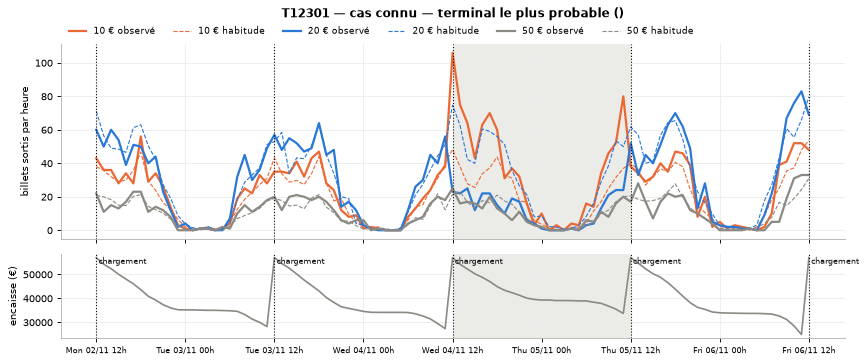

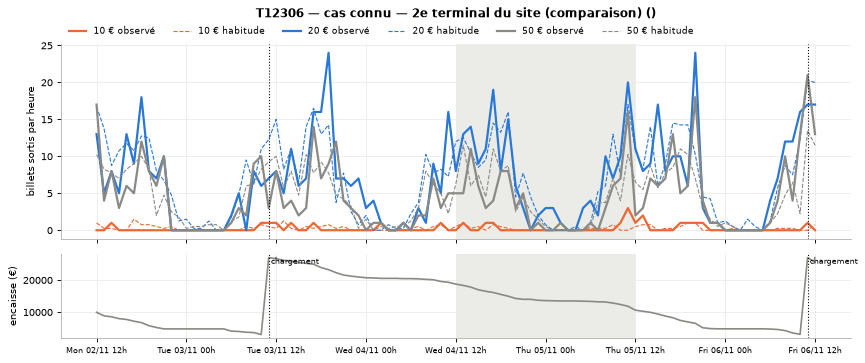

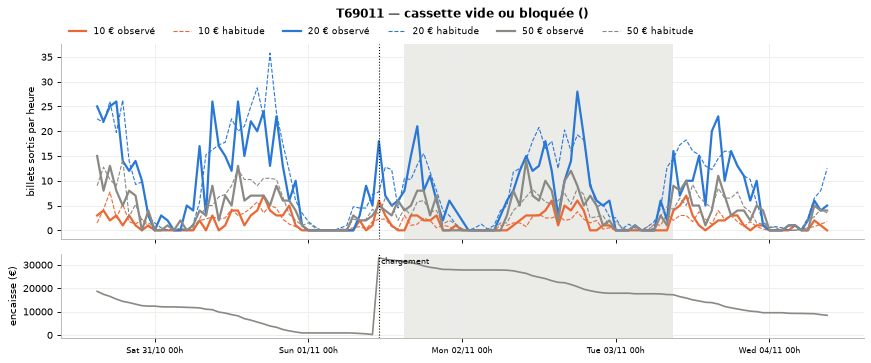

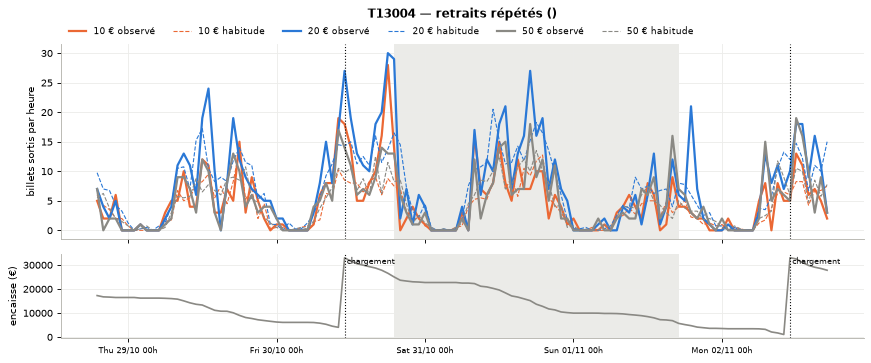

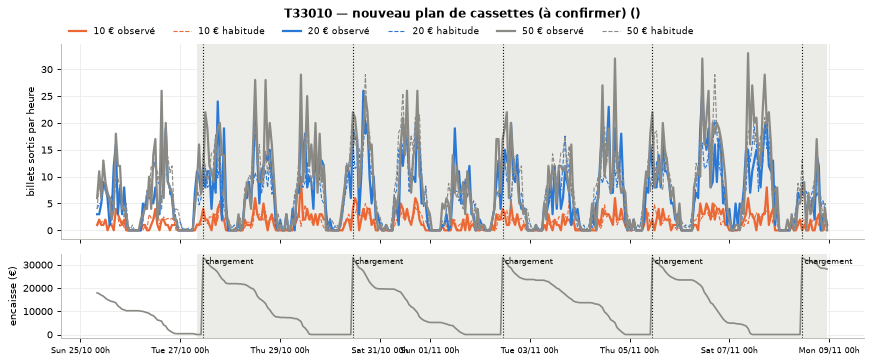

In [9]:
def tracer_coupures(terminal, d0, d1, titre=None):
    hab = habitude.loc[terminal]
    g = grille[grille["num_automate"] == terminal].set_index("ts")
    zone = g[(g.index >= d0 - pd.Timedelta(days=2)) & (g.index <= d1 + pd.Timedelta(days=1))]
    ref = g[g.index < DEBUT]
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
    coupures = sorted(set(hab[["val_ref_pos{}".format(k) for k in POSITIONS]].dropna().astype(int)))
    for c in coupures:
        cols = ["nb_billets_pos{}".format(k) for k in POSITIONS if hab["val_ref_pos{}".format(k)] == c]
        obs = zone[cols].sum(axis=1)
        moy = ref[cols].sum(axis=1).groupby([ref.index.dayofweek, ref.index.hour]).mean()
        attendu = [moy.get((t.dayofweek, t.hour), np.nan) for t in zone.index]
        couleur = COULEUR_COUPURE.get(c, ENCRE)
        ax.plot(zone.index, obs, color=couleur, linewidth=2, label="{} € observé".format(c))
        ax.plot(zone.index, attendu, color=couleur, linewidth=1, linestyle="--", label="{} € habitude".format(c))
    ax.axvspan(d0, d1, color=GRIS_CLAIR, alpha=0.5, linewidth=0)
    ax2.axvspan(d0, d1, color=GRIS_CLAIR, alpha=0.5, linewidth=0)
    ax2.plot(zone.index, zone["encaisse_max_heure"].ffill(), color=GRIS, linewidth=1.5)
    ax2.set_ylabel("encaisse (€)")
    for t in zone.index[zone["nb_recharges"] > 0]:
        for a in (ax, ax2):
            a.axvline(t, color=ENCRE, linewidth=1, linestyle=":")
        ax2.annotate("chargement", (t, 1), xycoords=("data", "axes fraction"), xytext=(2, -9),
                     textcoords="offset points", fontsize=7, color=ENCRE)
    ax.set_ylabel("billets sortis par heure")
    ax.set_title(titre or "{} — billets sortis par coupure".format(terminal), pad=24)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m %Hh"))
    ax.legend(ncol=6, fontsize=8, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0))
    for e in ax2.get_xticklabels():
        e.set_fontsize(7)
    fig.tight_layout()
    plt.show()


a_tracer = []
if len(candidats):
    a_tracer.append((candidats.iloc[0]["num_automate"], pd.Timestamp(CAS_CONNU["debut"]),
                     pd.Timestamp(CAS_CONNU["fin"]), "cas connu — terminal le plus probable"))
    if len(candidats) > 1:
        a_tracer.append((candidats.iloc[1]["num_automate"], pd.Timestamp(CAS_CONNU["debut"]),
                         pd.Timestamp(CAS_CONNU["fin"]), "cas connu — 2e terminal du site (comparaison)"))
for _, ev in evenements.head(4).iterrows() if len(evenements) else []:
    if ev["num_automate"] not in [a[0] for a in a_tracer]:
        a_tracer.append((ev["num_automate"], ev["alerte du"], ev["au"], ev["lecture proposée"]))
for terminal, d0, d1, libelle in a_tracer:
    tracer_coupures(terminal, d0, d1, "{} — {} ({})".format(terminal, libelle, infos.loc[terminal, "ville"]))

## 9. Synthèse et export

In [10]:
afficher_chiffres({"terminal analysés": grille["num_automate"].nunique(),
                   "événements": len(evenements),
                   "inversions 10/20 possibles": int((evenements["lecture proposée"] == "inversion 10 € / 20 € possible").sum())
                   if len(evenements) else 0,
                   "erreurs de paramétrage": int(evenements["lecture proposée"].str.startswith("erreur").sum())
                   if len(evenements) else 0,
                   "cassettes vides ou bloquées": int((evenements["lecture proposée"] == "cassette vide ou bloquée").sum())
                   if len(evenements) else 0},
                  "Synthèse")
if len(evenements):
    for _, ev in evenements.head(10).iterrows():
        texte = "<b>{}</b> ({}) : {}, du {} au {} ; position {} sortie à {:.0f} % au lieu de {:.0f} %".format(
            ev["num_automate"], ev["ville"], ev["lecture proposée"], formater(ev["alerte du"]), formater(ev["au"]),
            ev["position en cause"], ev["part observée %"], ev["part habituelle %"])
        if ev["chargement au début"] != "non":
            texte += " ; chargement au début : {}".format(ev["chargement au début"])
        if not pd.isna(ev["perte si inversion 10/20 (€)"]) and ev["lecture proposée"].startswith("inversion"):
            texte += " ; perte estimée si l'inversion est confirmée : {} €".format(formater(ev["perte si inversion 10/20 (€)"]))
        display(HTML(CSS + "<div class='note'>{}</div>".format(texte)))
if DATASET_SORTIE_EVENEMENTS and len(evenements):
    import dataiku
    sortie = evenements.copy()
    for c in ["alerte du", "au"]:
        sortie[c] = sortie[c].astype(str)
    dataiku.Dataset(DATASET_SORTIE_EVENEMENTS).write_with_schema(sortie)